# Task 1 — Financial Data Extraction & Analysis
**BCG X GenAI Job Simulation (Forage)**

**Objective:** Extract key financial metrics from the latest three annual 10-K filings of **Microsoft, Tesla and Apple**, then analyse trends to inform a GenAI-powered financial chatbot.

**Data source:** SEC EDGAR 10-K filings (fiscal years 2021–2023). All figures are in **USD millions**.

| Company | Fiscal year end | CIK |
|---|---|---|
| Microsoft | 30 June | 0000789019 |
| Tesla | 31 December | 0001318605 |
| Apple | Last Saturday of September | 0000320193 |

**Metrics extracted:** Total Revenue, Net Income, Total Assets, Total Liabilities, Cash Flow from Operating Activities.
> Tesla net income is *net income attributable to common stockholders*.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.2f}'.format)
df = pd.read_csv('../data/financial_data.csv')
df = df.sort_values(['Company', 'Fiscal Year']).reset_index(drop=True)
df

,Company,Fiscal Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Operating Activities
0,Apple,2021,365817,94680,351002,287912,104038
1,Apple,2022,394328,99803,352755,302083,122151
2,Apple,2023,383285,96995,352583,290437,110543
3,Microsoft,2021,168088,61271,333779,191791,76740
4,Microsoft,2022,198270,72738,364840,198298,89035
5,Microsoft,2023,211915,72361,411976,205753,87582
6,Tesla,2021,53823,5519,62131,30548,11497
7,Tesla,2022,81462,12556,82338,36440,14724
8,Tesla,2023,96773,14997,106618,43009,13256


## 1. Data quality checks

In [2]:
print(df.dtypes, '\n')
print('Missing values:', int(df.isna().sum().sum()))
print('Rows per company:\n', df['Company'].value_counts())
assert (df['Total Assets'] > df['Total Liabilities']).all(), 'Negative equity found'

Company                                  str
Fiscal Year                            int64
Total Revenue                          int64
Net Income                             int64
Total Assets                           int64
Total Liabilities                      int64
Cash Flow from Operating Activities    int64
dtype: object 

Missing values: 0
Rows per company:
 Company
Apple        3
Microsoft    3
Tesla        3
Name: count, dtype: int64


## 2. Year-over-year growth rates (%)

In [3]:
metrics = ['Total Revenue', 'Net Income', 'Total Assets', 'Total Liabilities',
           'Cash Flow from Operating Activities']
growth_cols = {m: m.replace('Cash Flow from Operating Activities', 'Operating Cash Flow') + ' Growth (%)'
               for m in metrics}
for m, col in growth_cols.items():
    df[col] = df.groupby('Company')[m].pct_change() * 100

df[['Company', 'Fiscal Year'] + list(growth_cols.values())]

,Company,Fiscal Year,Total Revenue Growth (%),Net Income Growth (%),Total Assets Growth (%),Total Liabilities Growth (%),Operating Cash Flow Growth (%)
0,Apple,2021,NaN,NaN,NaN,NaN,NaN
1,Apple,2022,7.79,5.41,0.50,4.92,17.41
2,Apple,2023,-2.80,-2.81,-0.05,-3.86,-9.50
3,Microsoft,2021,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2022,17.96,18.72,9.31,3.39,16.02
5,Microsoft,2023,6.88,-0.52,12.92,3.76,-1.63
6,Tesla,2021,NaN,NaN,NaN,NaN,NaN
7,Tesla,2022,51.35,127.50,32.52,19.29,28.07
8,Tesla,2023,18.80,19.44,29.49,18.03,-9.97


## 3. Profitability, leverage and cash-quality ratios

In [4]:
df['Net Profit Margin (%)'] = df['Net Income'] / df['Total Revenue'] * 100
df['Shareholders Equity'] = df['Total Assets'] - df['Total Liabilities']
df['Debt-to-Equity (x)'] = df['Total Liabilities'] / df['Shareholders Equity']
df['Return on Assets (%)'] = df['Net Income'] / df['Total Assets'] * 100
df['Cash Conversion (OCF / Net Income)'] = df['Cash Flow from Operating Activities'] / df['Net Income']

ratios = ['Net Profit Margin (%)', 'Debt-to-Equity (x)', 'Return on Assets (%)',
          'Cash Conversion (OCF / Net Income)']
df[['Company', 'Fiscal Year'] + ratios]

,Company,Fiscal Year,Net Profit Margin (%),Debt-to-Equity (x),Return on Assets (%),Cash Conversion (OCF / Net Income)
0,Apple,2021,25.88,4.56,26.97,1.10
1,Apple,2022,25.31,5.96,28.29,1.22
2,Apple,2023,25.31,4.67,27.51,1.14
3,Microsoft,2021,36.45,1.35,18.36,1.25
4,Microsoft,2022,36.69,1.19,19.94,1.22
5,Microsoft,2023,34.15,1.00,17.56,1.21
6,Tesla,2021,10.25,0.97,8.88,2.08
7,Tesla,2022,15.41,0.79,15.25,1.17
8,Tesla,2023,15.50,0.68,14.07,0.88


## 4. Summary across the three-year window

In [5]:
def cagr(s):
    return ((s.iloc[-1] / s.iloc[0]) ** (1 / (len(s) - 1)) - 1) * 100

summary = df.groupby('Company').agg(
    revenue_cagr=('Total Revenue', cagr),
    net_income_cagr=('Net Income', cagr),
    ocf_cagr=('Cash Flow from Operating Activities', cagr),
    avg_net_margin=('Net Profit Margin (%)', 'mean'),
    latest_debt_to_equity=('Debt-to-Equity (x)', 'last'),
)
summary.columns = ['Revenue CAGR 21-23 (%)', 'Net Income CAGR 21-23 (%)', 'Op. Cash Flow CAGR 21-23 (%)',
                   'Avg Net Margin (%)', 'Debt-to-Equity FY23 (x)']
summary

,Revenue CAGR 21-23 (%),Net Income CAGR 21-23 (%),Op. Cash Flow CAGR 21-23 (%),Avg Net Margin (%),Debt-to-Equity FY23 (x)
Company,,,,,
Apple,2.36,1.22,3.08,25.50,4.67
Microsoft,12.28,8.67,6.83,35.76,1.00
Tesla,34.09,64.84,7.38,13.72,0.68


## 5. Visual trends

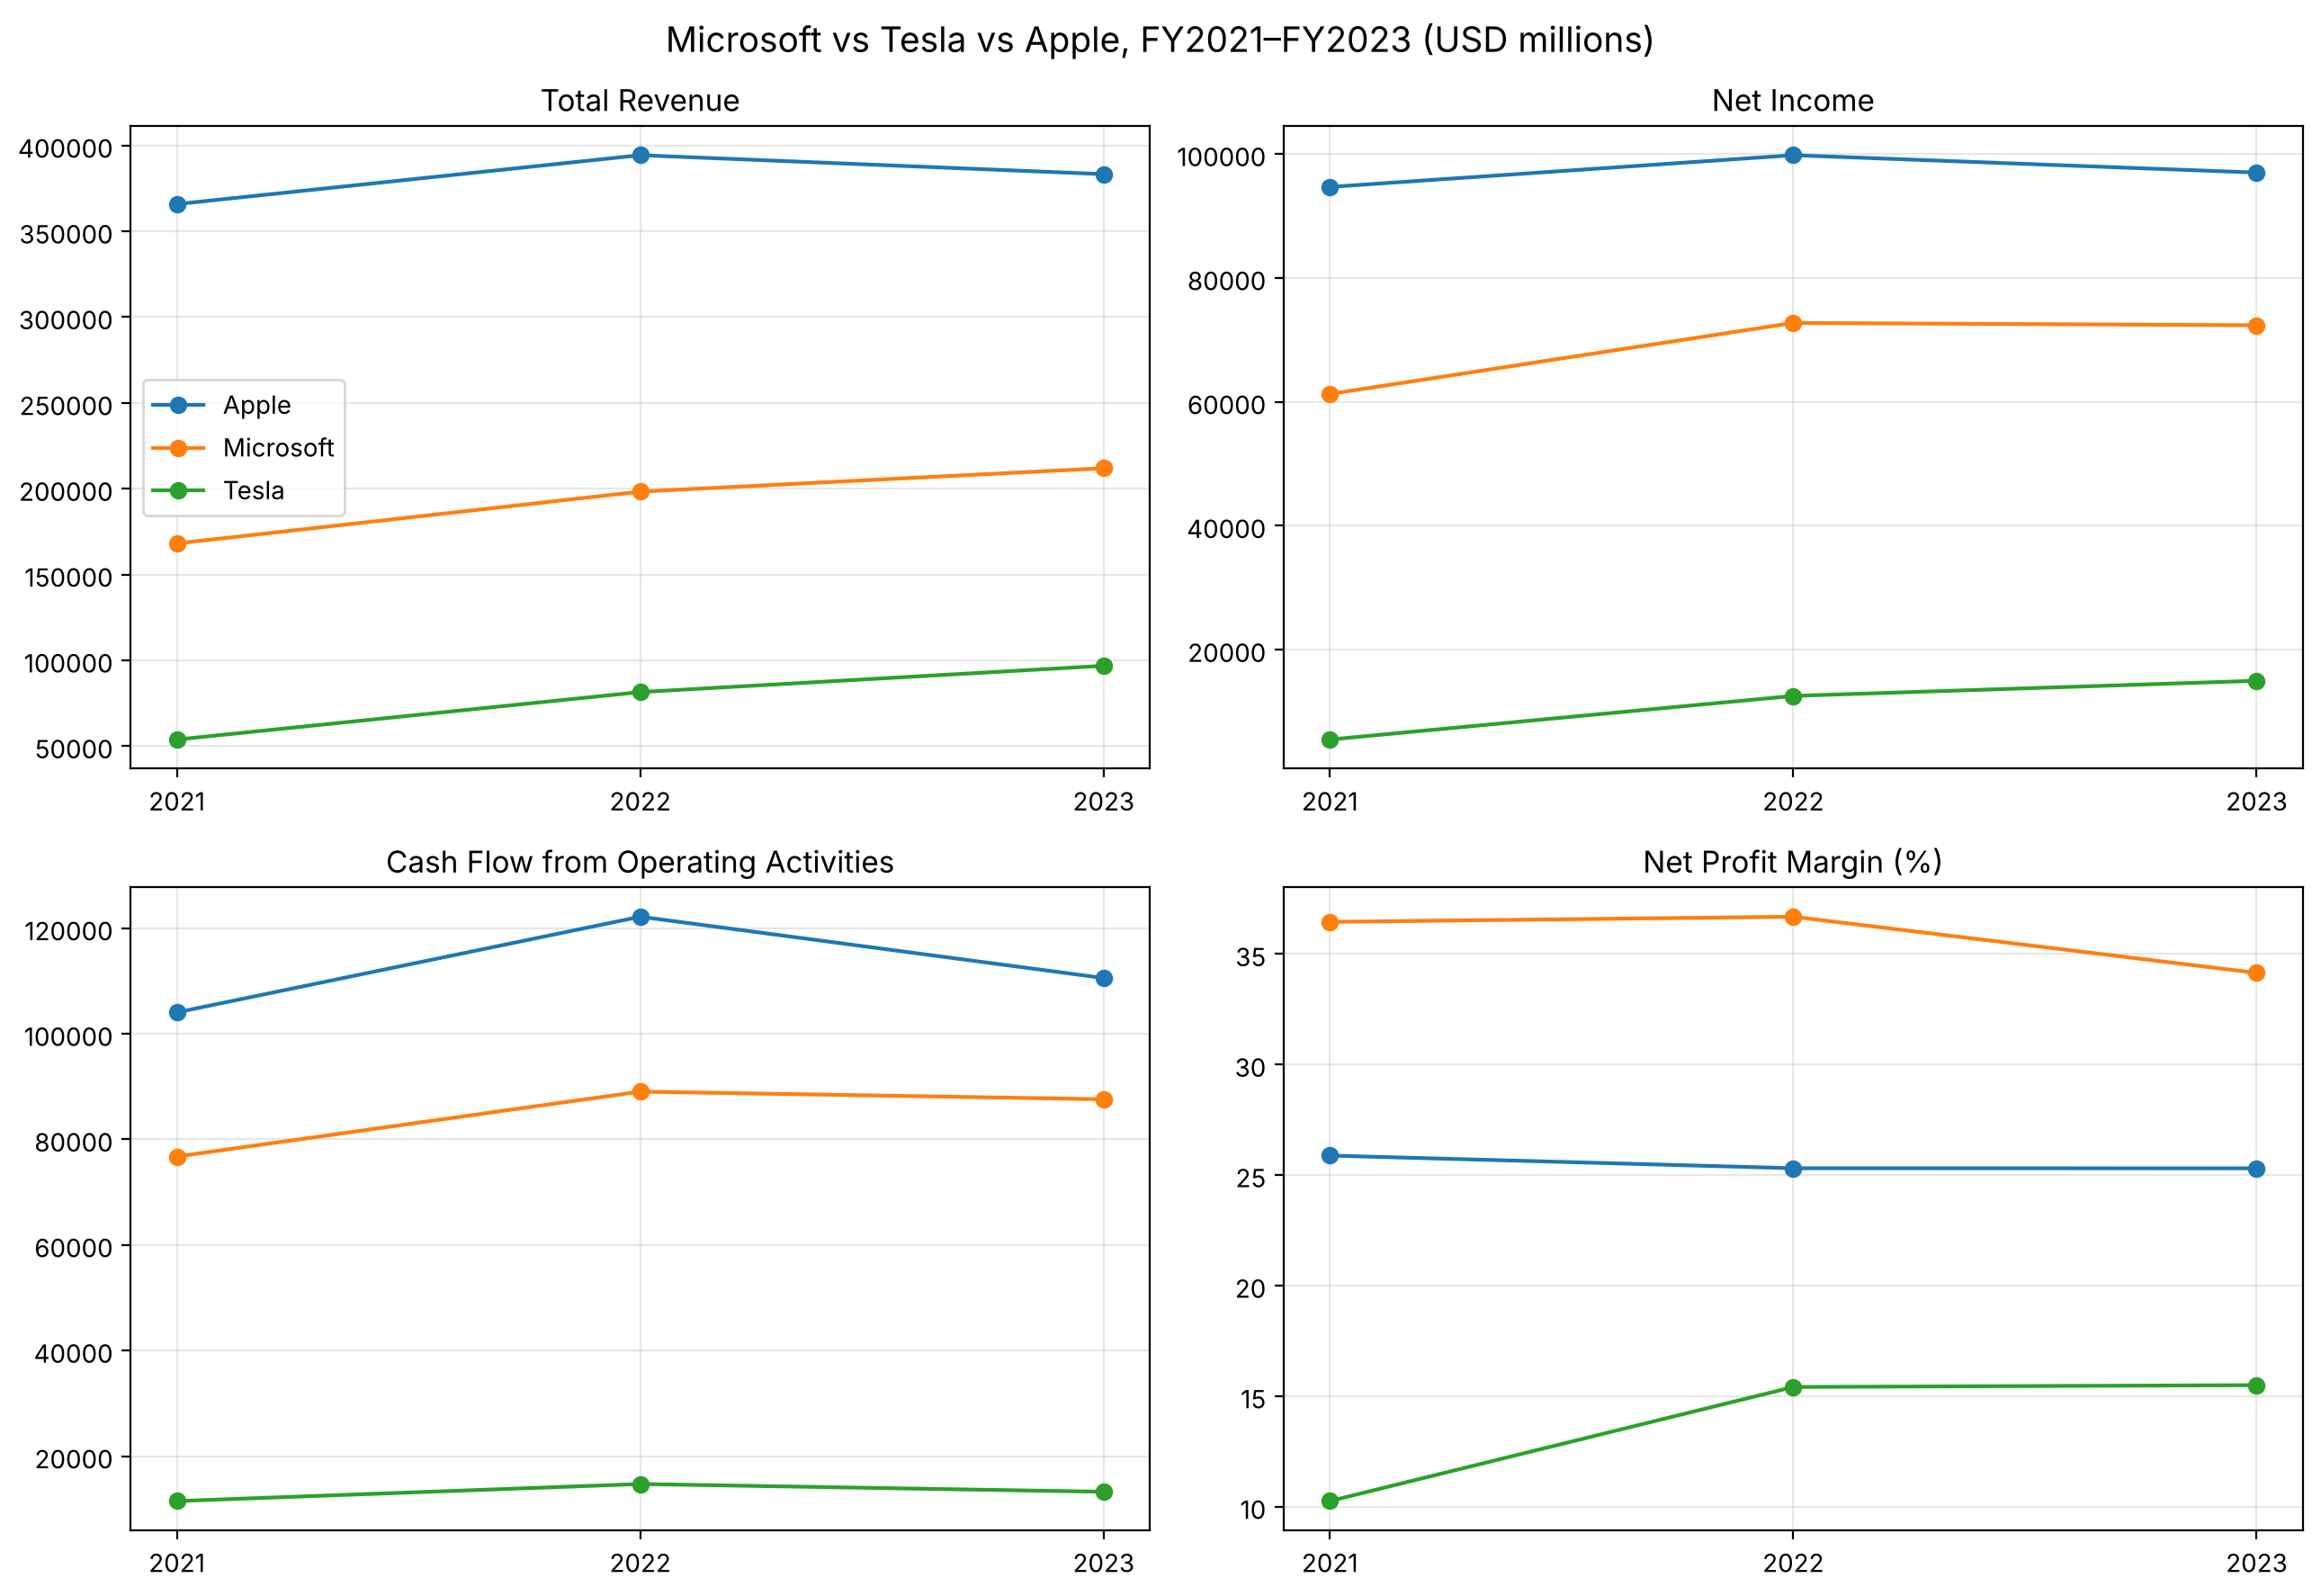

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.flat, ['Total Revenue', 'Net Income',
                                  'Cash Flow from Operating Activities', 'Net Profit Margin (%)']):
    for company, g in df.groupby('Company'):
        ax.plot(g['Fiscal Year'], g[metric], marker='o', label=company)
    ax.set_title(metric)
    ax.set_xticks([2021, 2022, 2023])
    ax.grid(alpha=.3)
axes[0, 0].legend()
plt.suptitle('Microsoft vs Tesla vs Apple, FY2021–FY2023 (USD millions)', fontsize=14)
plt.tight_layout()
plt.savefig('financial_trends.png', dpi=120)
plt.show()

## 6. Export for the chatbot (Task 2)

In [7]:
df.round(2).to_csv('../data/financial_analysis.csv', index=False)
print('Saved ../data/financial_analysis.csv with', df.shape[1], 'columns')

Saved ../data/financial_analysis.csv with 17 columns


## 7. Key findings

**Microsoft** — Strongest combination of growth and stability. Revenue grew from \$168.1B to \$211.9B (~12% CAGR). Net income was flat in FY23 (−0.5%) after +18.7% in FY22, as costs and macro headwinds offset revenue growth. Net margin stays above 34%, and debt-to-equity fell from ~1.35x to ~1.00x as equity grew faster than liabilities.

**Tesla** — Fastest grower. Revenue rose ~34% CAGR (\$53.8B → \$96.8B) and net income nearly tripled (\$5.5B → \$15.0B). However, operating cash flow *fell* 10% in FY23 while net income rose ~19% — the FY23 profit was boosted by a one-off deferred-tax-asset release, so earnings quality warrants scrutiny. Leverage is low (~0.68x D/E).

**Apple** — Largest by revenue but maturing. Revenue dipped −2.8% in FY23 and net income −2.8%, ending a growth run. Margins remain ~25% and cash generation is excellent (OCF > net income every year). Debt-to-equity is high (~4.7x) because Apple returns large amounts of capital via buybacks, shrinking equity.

**Implications for the chatbot:** users will most often ask about revenue, profit and their changes, so the dataset is pre-computed with YoY growth and ratios — the chatbot can answer instantly without recalculating.